In [22]:
import pandas as pd
import numpy as np

In [23]:
df = pd.read_csv('../data/population.csv')
df

,อำเภอ,ประชากร_2562,ประชากร_2563,ประชากร_2564,ประชากร_2565,ประชากร_2566,อัตราเพิ่ม_2563,อัตราเพิ่ม_2564,อัตราเพิ่ม_2565,อัตราเพิ่ม_2566,ความหนาแน่นประชากร_2566,District_English
0,รวมยอด,1265387,1276745,1288637,1295916,1308092,0.89,0.93,0.56,0.94,2102.03,Total
1,อำเภอเมืองนนทบุรี,367189,365288,364074,361127,359949,-0.52,-0.33,-0.81,-0.33,4674.66,Mueang Nonthaburi District
2,อำเภอบางกรวย,141149,144586,147182,149652,152508,2.41,1.78,1.66,1.89,2656.93,Bang Kruai District
3,อำเภอบางใหญ่,156861,160270,163797,166606,170223,2.15,2.18,1.70,2.15,1765.80,Bang Yai District
4,อำเภอบางบัวทอง,281766,285698,288592,290954,294818,1.39,1.01,0.82,1.32,2532.80,Bang Bua Thong District
5,อำเภอไทรน้อย,69007,70806,72822,74611,76440,2.57,2.81,2.43,2.42,410.97,Sai Noi District
6,อำเภอปากเกร็ด,249415,250097,252170,252966,254154,0.27,0.83,0.32,0.47,2855.66,Pak Kret District


In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   อำเภอ                    7 non-null      str    
 1   ประชากร_2562             7 non-null      int64  
 2   ประชากร_2563             7 non-null      int64  
 3   ประชากร_2564             7 non-null      int64  
 4   ประชากร_2565             7 non-null      int64  
 5   ประชากร_2566             7 non-null      int64  
 6   อัตราเพิ่ม_2563          7 non-null      float64
 7   อัตราเพิ่ม_2564          7 non-null      float64
 8   อัตราเพิ่ม_2565          7 non-null      float64
 9   อัตราเพิ่ม_2566          7 non-null      float64
 10  ความหนาแน่นประชากร_2566  7 non-null      float64
 11  District_English         7 non-null      str    
dtypes: float64(5), int64(5), str(2)
memory usage: 804.0 bytes


In [25]:
df = df.drop('District_English', axis=1)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   อำเภอ                    7 non-null      str    
 1   ประชากร_2562             7 non-null      int64  
 2   ประชากร_2563             7 non-null      int64  
 3   ประชากร_2564             7 non-null      int64  
 4   ประชากร_2565             7 non-null      int64  
 5   ประชากร_2566             7 non-null      int64  
 6   อัตราเพิ่ม_2563          7 non-null      float64
 7   อัตราเพิ่ม_2564          7 non-null      float64
 8   อัตราเพิ่ม_2565          7 non-null      float64
 9   อัตราเพิ่ม_2566          7 non-null      float64
 10  ความหนาแน่นประชากร_2566  7 non-null      float64
dtypes: float64(5), int64(5), str(1)
memory usage: 748.0 bytes


In [26]:
df.head()

,อำเภอ,ประชากร_2562,ประชากร_2563,ประชากร_2564,ประชากร_2565,ประชากร_2566,อัตราเพิ่ม_2563,อัตราเพิ่ม_2564,อัตราเพิ่ม_2565,อัตราเพิ่ม_2566,ความหนาแน่นประชากร_2566
0,รวมยอด,1265387,1276745,1288637,1295916,1308092,0.89,0.93,0.56,0.94,2102.03
1,อำเภอเมืองนนทบุรี,367189,365288,364074,361127,359949,-0.52,-0.33,-0.81,-0.33,4674.66
2,อำเภอบางกรวย,141149,144586,147182,149652,152508,2.41,1.78,1.66,1.89,2656.93
3,อำเภอบางใหญ่,156861,160270,163797,166606,170223,2.15,2.18,1.70,2.15,1765.80
4,อำเภอบางบัวทอง,281766,285698,288592,290954,294818,1.39,1.01,0.82,1.32,2532.80


In [27]:
df.to_csv('../clean_data/clean_population.csv')

In [28]:
import matplotlib.pyplot as plt
import seaborn as sbs

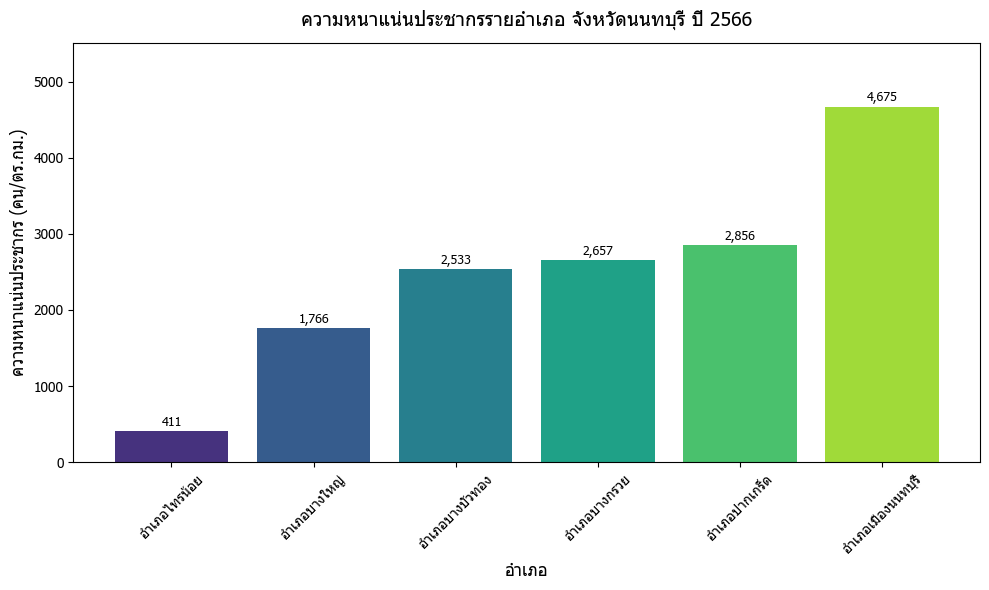

In [34]:
# ตั้งค่าฟอนต์ภาษาไทย (Windows มี Tahoma รองรับภาษาไทย)
plt.rcParams['font.family'] = 'Tahoma'
plt.rcParams['axes.unicode_minus'] = False

# ตัดแถว "รวมยอด" ออก เพื่อเปรียบเทียบเฉพาะรายอำเภอ
density = (
    df[df['อำเภอ'] != 'รวมยอด']
    .sort_values('ความหนาแน่นประชากร_2566', ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(
    density['อำเภอ'],
    density['ความหนาแน่นประชากร_2566'],
    color=sbs.color_palette('viridis', len(density)),
)

# กำกับค่าที่ปลายแท่ง
for bar, value in zip(bars, density['ความหนาแน่นประชากร_2566']):
    ax.text(
        bar.get_x() + bar.get_width() / 2, value + 30,
        f'{value:,.0f}',
        ha='center', va='bottom', fontsize=9,
    )

ax.set_title('ความหนาแน่นประชากรรายอำเภอ จังหวัดนนทบุรี ปี 2566', fontsize=14, pad=12)
ax.set_ylabel('ความหนาแน่นประชากร (คน/ตร.กม.)', fontsize=12)
ax.set_xlabel('อำเภอ', fontsize=12)
ax.tick_params(axis='x', rotation=45)
ax.margins(y=0.18)
plt.tight_layout()
plt.show()